# 08. Final Evaluation

Open QSM MP-PCA 결과를 최종 평가한다.

평가 대상:

- Noisy baseline
- Magnitude MP-PCA
- Real / Imaginary Split MP-PCA
- Real + Imaginary Combined MP-PCA
- Direct Complex MP-PCA
- Complex Wishart MP-PCA

Noise level:

- 10%
- 30%
- 50%

평가 metric:

- PSNR
- SSIM
- NRMSE
- HFEN

이 notebook은 **서버용 multiprocessing을 사용하지 않는다.**
`Open-QSM-MP-PCA` 프로젝트 폴더 안에서 실행하면 로컬의 `./data`를 읽고
`./results/evaluation`에 결과를 저장한다.

평가 원칙:

- 모든 방법은 magnitude 기준 비교
- clean reference = `abs(meas_gre)`
- complex 결과 = `abs(deno_complex)`
- brain mask는 **오직 최종 평가 ROI에만 사용**
- 5개 echo 각각 metric 계산
- 각 noise level × method에 대해 5-echo 평균 계산


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.io as sio
from scipy.ndimage import gaussian_laplace
import matplotlib.pyplot as plt

from skimage.metrics import structural_similarity


C:\Users\653wa\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
C:\Users\653wa\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
C:\Users\653wa\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


## 1. 경로 설정

아래와 같은 프로젝트 구조를 기준으로 한다.

```text
Open-QSM-MP-PCA/
├─ data/
│  ├─ processed/
│  ├─ noisy_data/
│  └─ denoised/
│     ├─ magnitude/
│     ├─ real_imag/
│     ├─ real_imag_combined/
│     ├─ direct_complex/
│     └─ complex_wishart/
└─ results/
```

Notebook을 `Open-QSM-MP-PCA` 프로젝트 루트에서 실행한다.


In [4]:
NOISE_LEVELS = [10, 30, 50]
N_ECHO = 5

SSIM_SIGMA = 1.5
HFEN_SIGMA = 1.5

PROJECT_DIR = Path.cwd().resolve()
DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
NOISY_DIR = DATA_DIR / "noisy_data"
DENOISED_DIR = DATA_DIR / "denoised"

RESULT_DIR = PROJECT_DIR / "results" / "evaluation"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

CLEAN_PATH = (
    PROCESSED_DIR /
    "qsm_consensus_siemens_monopolar_complex.npz"
)

print("Project directory :", PROJECT_DIR)
print("Data directory    :", DATA_DIR)
print("Result directory  :", RESULT_DIR)
print("Clean reference   :", CLEAN_PATH)


Project directory : C:\Users\653wa\git\Graduation-Thesis\Open-QSM-MP-PCA
Data directory    : C:\Users\653wa\git\Graduation-Thesis\Open-QSM-MP-PCA\data
Result directory  : C:\Users\653wa\git\Graduation-Thesis\Open-QSM-MP-PCA\results\evaluation
Clean reference   : C:\Users\653wa\git\Graduation-Thesis\Open-QSM-MP-PCA\data\processed\qsm_consensus_siemens_monopolar_complex.npz


## 2. Clean reference + evaluation brain mask 로드

In [6]:
if not CLEAN_PATH.exists():
    raise FileNotFoundError(
        f"Clean reference를 찾을 수 없습니다:\n{CLEAN_PATH}"
    )

clean_npz = np.load(CLEAN_PATH, allow_pickle=False)

clean_complex = clean_npz["meas_gre"].astype(np.complex64)
mask_brain = clean_npz["mask_brain"].astype(bool)

if clean_complex.ndim != 4:
    raise ValueError(
        f"clean data가 4D가 아닙니다: {clean_complex.shape}"
    )

if clean_complex.shape[-1] != N_ECHO:
    raise ValueError(
        f"{N_ECHO} echoes 예상, 실제={clean_complex.shape[-1]}"
    )

if mask_brain.shape != clean_complex.shape[:3]:
    raise ValueError(
        f"Mask shape mismatch: {mask_brain.shape} "
        f"vs {clean_complex.shape[:3]}"
    )

clean_mag = np.abs(clean_complex).astype(np.float32)

print("Clean complex shape :", clean_complex.shape)
print("Clean magnitude     :", clean_mag.shape)
print("Brain mask shape    :", mask_brain.shape)
print("Brain mask voxels   :", int(mask_brain.sum()))


Clean complex shape : (176, 256, 144, 5)
Clean magnitude     : (176, 256, 144, 5)
Brain mask shape    : (176, 256, 144)
Brain mask voxels   : 1780588


## 3. Denoising 결과 파일 정의

지금까지 만든 결과 폴더 및 파일명에 맞춘다.


In [8]:
METHOD_SPECS = {
    "Noisy": {
        "kind": "npz_noisy",
    },

    "Magnitude": {
        "kind": "magnitude",
        "folder": "magnitude",
        "key": "magnitude_denoised",
        "filename": "denoised_magnitude_{noise}_r3.mat",
    },

    "Real_Imag": {
        "kind": "complex",
        "folder": "real_imag",
        "key": "deno_complex",
        "filename": "denoised_real_imag_{noise}_r3.mat",
    },

    "Real_Imag_Combined": {
        "kind": "complex",
        "folder": "real_imag_combined",
        "key": "deno_complex",
        "filename": "denoised_real_imag_combined_{noise}_r3.mat",
    },

    "Direct_Complex": {
        "kind": "complex",
        "folder": "direct_complex",
        "key": "deno_complex",
        "filename": "denoised_direct_complex_{noise}_r3.mat",
    },

    "Complex_Wishart": {
        "kind": "complex",
        "folder": "complex_wishart",
        "key": "denoised_complex",
        "filename": "denoised_complex_wishart_{noise}_r3_a0.99.mat",
    },
}

for method, spec in METHOD_SPECS.items():
    print(method, "->", spec)


Noisy -> {'kind': 'npz_noisy'}
Magnitude -> {'kind': 'magnitude', 'folder': 'magnitude', 'key': 'magnitude_denoised', 'filename': 'denoised_magnitude_{noise}_r3.mat'}
Real_Imag -> {'kind': 'complex', 'folder': 'real_imag', 'key': 'deno_complex', 'filename': 'denoised_real_imag_{noise}_r3.mat'}
Real_Imag_Combined -> {'kind': 'complex', 'folder': 'real_imag_combined', 'key': 'deno_complex', 'filename': 'denoised_real_imag_combined_{noise}_r3.mat'}
Direct_Complex -> {'kind': 'complex', 'folder': 'direct_complex', 'key': 'deno_complex', 'filename': 'denoised_direct_complex_{noise}_r3.mat'}
Complex_Wishart -> {'kind': 'complex', 'folder': 'complex_wishart', 'key': 'denoised_complex', 'filename': 'denoised_complex_wishart_{noise}_r3_a0.99.mat'}


## 4. 모든 입력 결과 파일 존재 여부 확인

평가 전에 필요한 파일이 모두 있는지 먼저 확인한다.


In [10]:
missing_files = []

for noise_level in NOISE_LEVELS:
    noisy_path = (
        NOISY_DIR /
        f"qsm_siemens_monopolar_noisy_{noise_level}.npz"
    )

    if not noisy_path.exists():
        missing_files.append(noisy_path)

    for method, spec in METHOD_SPECS.items():
        if method == "Noisy":
            continue

        path = (
            DENOISED_DIR /
            spec["folder"] /
            spec["filename"].format(noise=noise_level)
        )

        if not path.exists():
            missing_files.append(path)

if missing_files:
    print("찾을 수 없는 파일:")
    for p in missing_files:
        print(" -", p)

    raise FileNotFoundError(
        f"총 {len(missing_files)}개의 결과 파일이 없습니다."
    )

print("모든 평가 입력 파일 확인 완료")


모든 평가 입력 파일 확인 완료


## 5. Metric 함수

### PSNR

Clean brain ROI의 echo별 `data_range = max(clean) - min(clean)`를 사용한다.

### SSIM

각 echo에 대해 axial slice 단위로 2D SSIM map을 계산한다.

- `gaussian_weights=True`
- `sigma=1.5`
- `use_sample_covariance=False`
- `full=True`

그 후 SSIM map에서 brain-mask voxel만 모아 전체 voxel-weighted mean을 계산한다.

### NRMSE

\[
NRMSE = \frac{||x-y||_2}{||x||_2}
\]

### HFEN

3D Laplacian-of-Gaussian, `sigma=1.5`를 적용하고 brain mask 내부에서

\[
HFEN = \frac{||LoG(y)-LoG(x)||_2}{||LoG(x)||_2}
\]

로 계산한다.


In [12]:
def get_data_range(ref3d, mask3d):
    vals = ref3d[mask3d].astype(np.float64)

    if vals.size == 0:
        raise ValueError("Brain mask가 비어 있습니다.")

    data_range = float(vals.max() - vals.min())

    if data_range <= 0 or not np.isfinite(data_range):
        raise ValueError(
            f"Invalid data_range: {data_range}"
        )

    return data_range


def calc_psnr(ref3d, test3d, mask3d, data_range):
    ref_roi = ref3d[mask3d].astype(np.float64)
    test_roi = test3d[mask3d].astype(np.float64)

    mse = np.mean((test_roi - ref_roi) ** 2)

    if mse == 0:
        return np.inf

    return float(
        20.0 * np.log10(data_range)
        - 10.0 * np.log10(mse)
    )


def calc_ssim(
    ref3d,
    test3d,
    mask3d,
    data_range,
    sigma=1.5
):
    total_ssim = 0.0
    total_voxels = 0

    for z in range(ref3d.shape[2]):
        mask2d = mask3d[:, :, z]

        if not np.any(mask2d):
            continue

        _, ssim_map = structural_similarity(
            ref3d[:, :, z],
            test3d[:, :, z],
            data_range=data_range,
            gaussian_weights=True,
            sigma=sigma,
            use_sample_covariance=False,
            full=True,
            channel_axis=None,
        )

        roi_ssim = ssim_map[mask2d]
        finite = np.isfinite(roi_ssim)

        total_ssim += np.sum(
            roi_ssim[finite],
            dtype=np.float64
        )
        total_voxels += int(np.sum(finite))

    if total_voxels == 0:
        return np.nan

    return float(total_ssim / total_voxels)


def calc_nrmse(ref3d, test3d, mask3d):
    ref_roi = ref3d[mask3d].astype(np.float64)
    test_roi = test3d[mask3d].astype(np.float64)

    denom = np.linalg.norm(ref_roi)

    if denom == 0:
        return np.nan

    return float(
        np.linalg.norm(test_roi - ref_roi) / denom
    )


def calc_hfen(
    ref3d,
    test3d,
    mask3d,
    sigma=1.5
):
    ref_log = gaussian_laplace(
        ref3d.astype(np.float64),
        sigma=sigma
    )

    test_log = gaussian_laplace(
        test3d.astype(np.float64),
        sigma=sigma
    )

    ref_roi = ref_log[mask3d]
    test_roi = test_log[mask3d]

    denom = np.linalg.norm(ref_roi)

    if denom == 0:
        return np.nan

    return float(
        np.linalg.norm(test_roi - ref_roi) / denom
    )


def evaluate_echo(ref3d, test3d, mask3d):
    data_range = get_data_range(ref3d, mask3d)

    return {
        "PSNR": calc_psnr(
            ref3d,
            test3d,
            mask3d,
            data_range
        ),

        "SSIM": calc_ssim(
            ref3d,
            test3d,
            mask3d,
            data_range,
            sigma=SSIM_SIGMA
        ),

        "NRMSE": calc_nrmse(
            ref3d,
            test3d,
            mask3d
        ),

        "HFEN": calc_hfen(
            ref3d,
            test3d,
            mask3d,
            sigma=HFEN_SIGMA
        ),

        "DataRange": data_range,
    }


## 6. Method 결과를 magnitude로 통일하여 로드

In [14]:
def load_method_magnitude(noise_level, method):
    spec = METHOD_SPECS[method]

    if method == "Noisy":
        path = (
            NOISY_DIR /
            f"qsm_siemens_monopolar_noisy_{noise_level}.npz"
        )

        d = np.load(path, allow_pickle=False)

        arr = np.abs(
            d["noisy_complex"].astype(np.complex64)
        ).astype(np.float32)

    else:
        path = (
            DENOISED_DIR /
            spec["folder"] /
            spec["filename"].format(noise=noise_level)
        )

        d = sio.loadmat(path)

        key = spec["key"]

        if key not in d:
            raise KeyError(
                f"{path.name}에 '{key}'가 없습니다.\n"
                f"Keys: {list(d.keys())}"
            )

        raw = d[key]

        if spec["kind"] == "magnitude":
            arr = np.asarray(
                raw,
                dtype=np.float32
            )

        elif spec["kind"] == "complex":
            arr = np.abs(
                np.asarray(
                    raw,
                    dtype=np.complex64
                )
            ).astype(np.float32)

        else:
            raise ValueError(
                f"Unknown kind: {spec['kind']}"
            )

    if arr.shape != clean_mag.shape:
        raise ValueError(
            f"{method}, Noise {noise_level}% shape mismatch:\n"
            f"{arr.shape} != {clean_mag.shape}"
        )

    return arr, path


## 7. 순차 평가 실행

10% → 30% → 50% 순서로 평가한다.

각 noise level에서:

```text
Noisy
Magnitude
Real_Imag
Real_Imag_Combined
Direct_Complex
Complex_Wishart
```

순서로 평가한다.


In [16]:
rows = []

for noise_level in NOISE_LEVELS:

    print("\n" + "=" * 80)
    print(f"Noise {noise_level}% 평가 시작")
    print("=" * 80)

    for method in METHOD_SPECS.keys():

        test_mag, source_path = load_method_magnitude(
            noise_level,
            method
        )

        print(f"  {method}")

        for echo_idx in range(N_ECHO):

            metrics = evaluate_echo(
                clean_mag[..., echo_idx],
                test_mag[..., echo_idx],
                mask_brain
            )

            rows.append({
                "NoiseLevel": noise_level,
                "Method": method,
                "Echo": echo_idx + 1,
                "PSNR": metrics["PSNR"],
                "SSIM": metrics["SSIM"],
                "NRMSE": metrics["NRMSE"],
                "HFEN": metrics["HFEN"],
                "DataRange": metrics["DataRange"],
                "SourceFile": str(source_path),
            })

            print(
                f"    Echo {echo_idx + 1} | "
                f"PSNR={metrics['PSNR']:.4f} | "
                f"SSIM={metrics['SSIM']:.6f} | "
                f"NRMSE={metrics['NRMSE']:.6f} | "
                f"HFEN={metrics['HFEN']:.6f}"
            )

        del test_mag

    print(f"Noise {noise_level}% 평가 완료")

echo_df = pd.DataFrame(rows)

echo_df = echo_df.sort_values(
    ["NoiseLevel", "Method", "Echo"]
).reset_index(drop=True)

echo_df



Noise 10% 평가 시작
  Noisy
    Echo 1 | PSNR=43.9105 | SSIM=0.975076 | NRMSE=0.031292 | HFEN=0.045434
    Echo 2 | PSNR=44.9696 | SSIM=0.978461 | NRMSE=0.035033 | HFEN=0.048347
    Echo 3 | PSNR=43.5675 | SSIM=0.971990 | NRMSE=0.039137 | HFEN=0.052166
    Echo 4 | PSNR=41.0558 | SSIM=0.957871 | NRMSE=0.043516 | HFEN=0.056403
    Echo 5 | PSNR=40.1757 | SSIM=0.951752 | NRMSE=0.048372 | HFEN=0.061024
  Magnitude
    Echo 1 | PSNR=45.0460 | SSIM=0.982154 | NRMSE=0.027457 | HFEN=0.043531
    Echo 2 | PSNR=47.4890 | SSIM=0.989024 | NRMSE=0.026213 | HFEN=0.041786
    Echo 3 | PSNR=46.2835 | SSIM=0.986490 | NRMSE=0.028628 | HFEN=0.045416
    Echo 4 | PSNR=43.4181 | SSIM=0.977546 | NRMSE=0.033154 | HFEN=0.050950
    Echo 5 | PSNR=41.7706 | SSIM=0.968777 | NRMSE=0.040258 | HFEN=0.057939
  Real_Imag
    Echo 1 | PSNR=44.8441 | SSIM=0.981592 | NRMSE=0.028103 | HFEN=0.047119
    Echo 2 | PSNR=46.9463 | SSIM=0.987635 | NRMSE=0.027903 | HFEN=0.045731
    Echo 3 | PSNR=45.2142 | SSIM=0.983750 | NRMSE=0

,NoiseLevel,Method,Echo,PSNR,SSIM,NRMSE,HFEN,DataRange,SourceFile
0,10,Complex_Wishart,1,45.007596,0.981897,0.027579,0.043542,1928.000000,C:\Users\653wa\git\Graduation-Thesis\Open-QSM-...
1,10,Complex_Wishart,2,47.415125,0.988696,0.026436,0.041098,2177.000244,C:\Users\653wa\git\Graduation-Thesis\Open-QSM-...
2,10,Complex_Wishart,3,46.236047,0.986180,0.028784,0.044959,1853.000000,C:\Users\653wa\git\Graduation-Thesis\Open-QSM-...
3,10,Complex_Wishart,4,43.508972,0.977515,0.032809,0.050659,1386.000000,C:\Users\653wa\git\Graduation-Thesis\Open-QSM-...
4,10,Complex_Wishart,5,41.478793,0.965950,0.041633,0.057912,1253.000000,C:\Users\653wa\git\Graduation-Thesis\Open-QSM-...
...,...,...,...,...,...,...,...,...,...
85,50,Real_Imag_Combined,1,34.996452,0.886089,0.087323,0.164591,1928.000000,C:\Users\653wa\git\Graduation-Thesis\Open-QSM-...
86,50,Real_Imag_Combined,2,37.525506,0.914778,0.082544,0.137047,2177.000244,C:\Users\653wa\git\Graduation-Thesis\Open-QSM-...
87,50,Real_Imag_Combined,3,36.537966,0.896045,0.087915,0.140940,1853.000000,C:\Users\653wa\git\Graduation-Thesis\Open-QSM-...
88,50,Real_Imag_Combined,4,33.464319,0.836663,0.104287,0.160898,1386.000000,C:\Users\653wa\git\Graduation-Thesis\Open-QSM-...


## 8. Echo별 전체 결과 저장

In [18]:
echo_csv = (
    RESULT_DIR /
    "metrics_echo_level.csv"
)

echo_df.to_csv(
    echo_csv,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:", echo_csv)
print("Rows :", len(echo_df))


Saved: C:\Users\653wa\git\Graduation-Thesis\Open-QSM-MP-PCA\results\evaluation\metrics_echo_level.csv
Rows : 90


## 9. Noise level × Method의 5-echo 평균

In [20]:
summary_df = (
    echo_df
    .groupby(
        ["NoiseLevel", "Method"],
        as_index=False
    )[["PSNR", "SSIM", "NRMSE", "HFEN"]]
    .mean()
)

METHOD_ORDER = list(METHOD_SPECS.keys())

summary_df["Method"] = pd.Categorical(
    summary_df["Method"],
    categories=METHOD_ORDER,
    ordered=True
)

summary_df = summary_df.sort_values(
    ["NoiseLevel", "Method"]
).reset_index(drop=True)

summary_path = (
    RESULT_DIR /
    "metrics_summary_5echo_mean.csv"
)

summary_df.to_csv(
    summary_path,
    index=False,
    encoding="utf-8-sig"
)

summary_df.round({
    "PSNR": 4,
    "SSIM": 6,
    "NRMSE": 6,
    "HFEN": 6,
})


,NoiseLevel,Method,PSNR,SSIM,NRMSE,HFEN
0,10,Noisy,42.7358,0.967030,0.039470,0.052675
1,10,Magnitude,44.8014,0.980798,0.031142,0.047924
2,10,Real_Imag,43.9982,0.977656,0.034397,0.060629
3,10,Real_Imag_Combined,44.9740,0.981194,0.030593,0.045594
4,10,Direct_Complex,44.7212,0.980040,0.031477,0.047329
5,10,Complex_Wishart,44.7293,0.980048,0.031448,0.047634
6,30,Noisy,33.2110,0.783324,0.118167,0.161567
7,30,Magnitude,37.6991,0.920571,0.070447,0.115753
8,30,Real_Imag,36.8031,0.898002,0.078677,0.123472
9,30,Real_Imag_Combined,37.8448,0.918810,0.069677,0.107424


## 10. Noise level별 PSNR / SSIM / NRMSE / HFEN 표

In [22]:
metric_tables = {}

for metric in [
    "PSNR",
    "SSIM",
    "NRMSE",
    "HFEN"
]:

    table = summary_df.pivot(
        index="Method",
        columns="NoiseLevel",
        values=metric
    )

    metric_tables[metric] = table

    print("\n" + "=" * 60)
    print(metric)
    print("=" * 60)

    display(table.round(6))

    table.to_csv(
        RESULT_DIR /
        f"{metric.lower()}_table.csv",
        encoding="utf-8-sig"
    )



PSNR


NoiseLevel,10,30,50
Method,,,
Noisy,42.735813,33.210984,28.808638
Magnitude,44.801444,37.699123,34.387781
Real_Imag,43.998192,36.803095,33.573106
Real_Imag_Combined,44.974042,37.844823,34.770691
Direct_Complex,44.721207,37.372055,33.972765
Complex_Wishart,44.729307,37.396458,34.013027



SSIM


NoiseLevel,10,30,50
Method,,,
Noisy,0.967030,0.783324,0.595394
Magnitude,0.980798,0.920571,0.873626
Real_Imag,0.977656,0.898002,0.825004
Real_Imag_Combined,0.981194,0.918810,0.863698
Direct_Complex,0.980040,0.906309,0.826181
Complex_Wishart,0.980048,0.906669,0.827829



NRMSE


NoiseLevel,10,30,50
Method,,,
Noisy,0.039470,0.118167,0.196140
Magnitude,0.031142,0.070447,0.102955
Real_Imag,0.034397,0.078677,0.114122
Real_Imag_Combined,0.030593,0.069677,0.099202
Direct_Complex,0.031477,0.073642,0.109141
Complex_Wishart,0.031448,0.073435,0.108632



HFEN


NoiseLevel,10,30,50
Method,,,
Noisy,0.052675,0.161567,0.270386
Magnitude,0.047924,0.115753,0.182306
Real_Imag,0.060629,0.123472,0.185222
Real_Imag_Combined,0.045594,0.107424,0.161811
Direct_Complex,0.047329,0.111380,0.172450
Complex_Wishart,0.047634,0.111341,0.172247


## 11. Best denoising method 확인

Noisy baseline을 제외한다.

- PSNR: 높을수록 좋음
- SSIM: 높을수록 좋음
- NRMSE: 낮을수록 좋음
- HFEN: 낮을수록 좋음


In [24]:
denoising_df = summary_df[
    summary_df["Method"] != "Noisy"
].copy()

best_rows = []

for noise_level in NOISE_LEVELS:

    sub = denoising_df[
        denoising_df["NoiseLevel"] == noise_level
    ]

    for metric in ["PSNR", "SSIM"]:
        idx = sub[metric].idxmax()

        best_rows.append({
            "NoiseLevel": noise_level,
            "Metric": metric,
            "BestMethod": str(
                sub.loc[idx, "Method"]
            ),
            "Value": float(
                sub.loc[idx, metric]
            ),
        })

    for metric in ["NRMSE", "HFEN"]:
        idx = sub[metric].idxmin()

        best_rows.append({
            "NoiseLevel": noise_level,
            "Metric": metric,
            "BestMethod": str(
                sub.loc[idx, "Method"]
            ),
            "Value": float(
                sub.loc[idx, metric]
            ),
        })

best_df = pd.DataFrame(best_rows)

best_df.to_csv(
    RESULT_DIR /
    "best_method_by_noise.csv",
    index=False,
    encoding="utf-8-sig"
)

best_df


,NoiseLevel,Metric,BestMethod,Value
0,10,PSNR,Real_Imag_Combined,44.974042
1,10,SSIM,Real_Imag_Combined,0.981194
2,10,NRMSE,Real_Imag_Combined,0.030593
3,10,HFEN,Real_Imag_Combined,0.045594
4,30,PSNR,Real_Imag_Combined,37.844823
5,30,SSIM,Magnitude,0.920571
6,30,NRMSE,Real_Imag_Combined,0.069677
7,30,HFEN,Real_Imag_Combined,0.107424
8,50,PSNR,Real_Imag_Combined,34.770691
9,50,SSIM,Magnitude,0.873626


## 12. 결과 그래프 저장

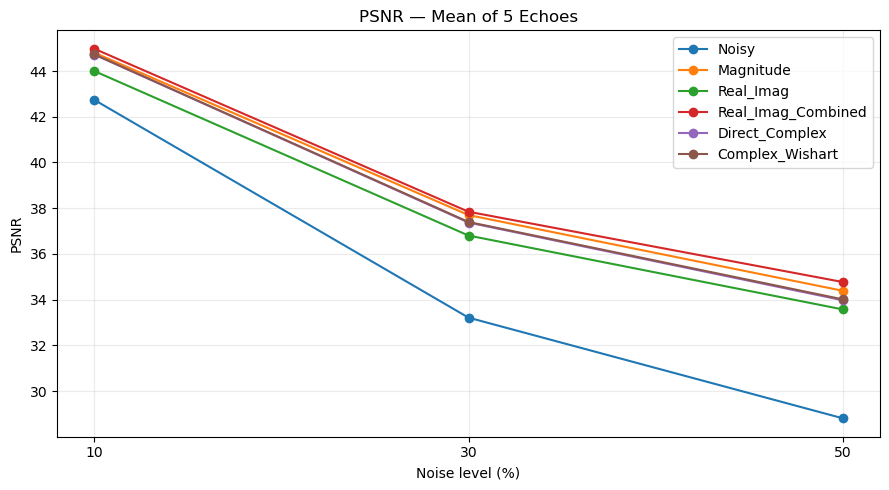

Saved: C:\Users\653wa\git\Graduation-Thesis\Open-QSM-MP-PCA\results\evaluation\psnr_plot.png


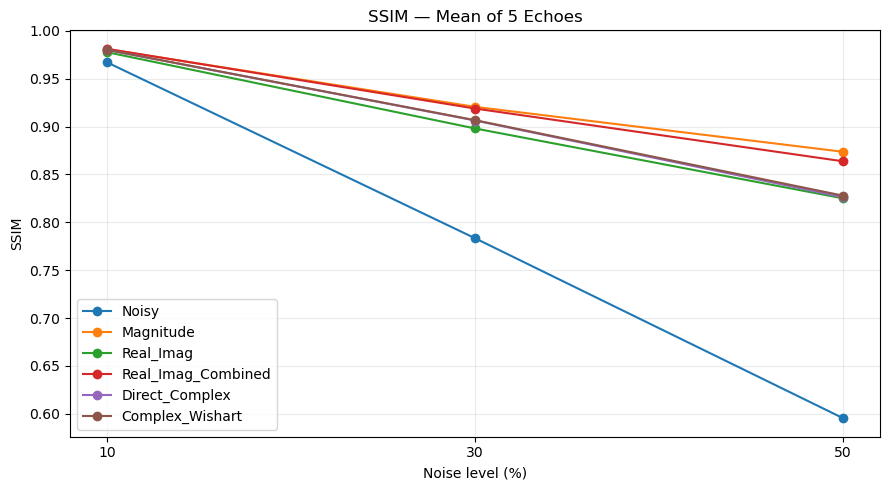

Saved: C:\Users\653wa\git\Graduation-Thesis\Open-QSM-MP-PCA\results\evaluation\ssim_plot.png


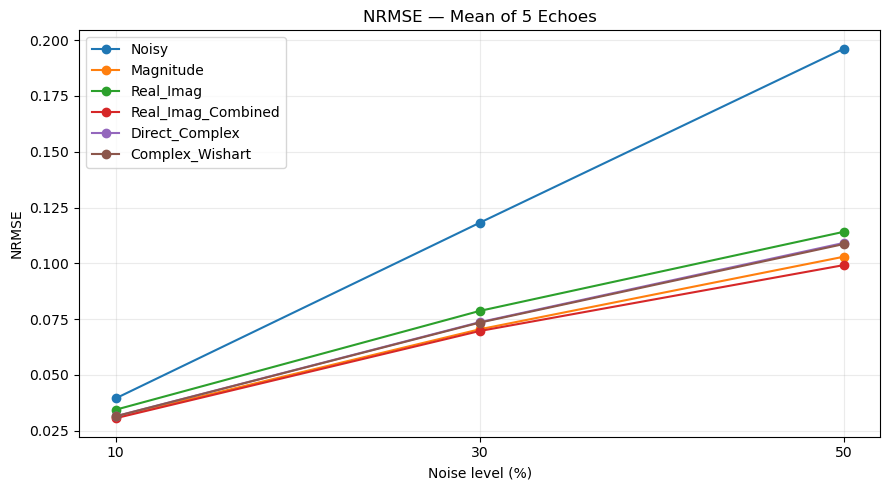

Saved: C:\Users\653wa\git\Graduation-Thesis\Open-QSM-MP-PCA\results\evaluation\nrmse_plot.png


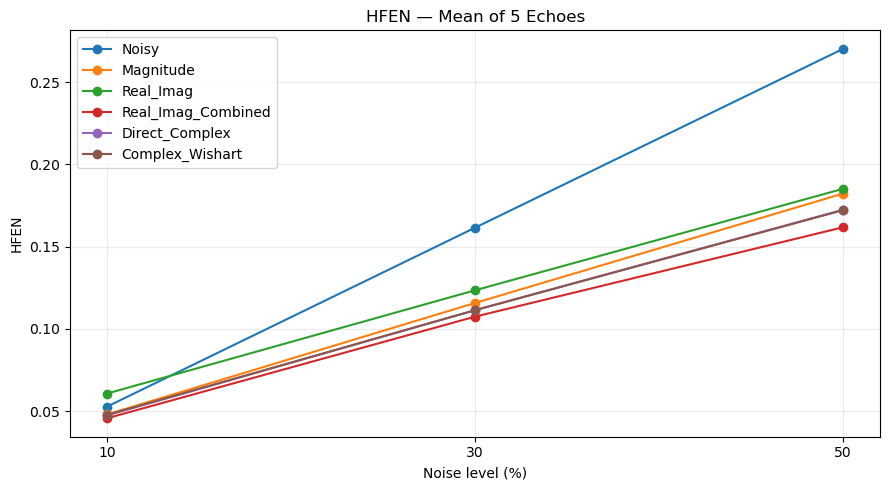

Saved: C:\Users\653wa\git\Graduation-Thesis\Open-QSM-MP-PCA\results\evaluation\hfen_plot.png


In [26]:
for metric in [
    "PSNR",
    "SSIM",
    "NRMSE",
    "HFEN"
]:

    plt.figure(figsize=(9, 5))

    for method in METHOD_ORDER:

        sub = summary_df[
            summary_df["Method"] == method
        ].sort_values("NoiseLevel")

        plt.plot(
            sub["NoiseLevel"],
            sub[metric],
            marker="o",
            label=method
        )

    plt.xlabel("Noise level (%)")
    plt.ylabel(metric)
    plt.title(f"{metric} — Mean of 5 Echoes")
    plt.xticks(NOISE_LEVELS)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()

    save_path = (
        RESULT_DIR /
        f"{metric.lower()}_plot.png"
    )

    plt.savefig(
        save_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", save_path)


## 13. 전체 noise level 평균

논문 핵심 결과는 noise level별 표를 사용하는 것을 권장한다.
아래 표는 전체적인 경향 확인용이다.


In [28]:
overall_df = (
    summary_df
    .groupby(
        "Method",
        observed=False,
        as_index=False
    )[["PSNR", "SSIM", "NRMSE", "HFEN"]]
    .mean()
)

overall_df.to_csv(
    RESULT_DIR /
    "metrics_overall_mean.csv",
    index=False,
    encoding="utf-8-sig"
)

overall_df.round(6)


,Method,PSNR,SSIM,NRMSE,HFEN
0,Noisy,34.918478,0.781916,0.117926,0.161543
1,Magnitude,38.962783,0.924999,0.068181,0.115328
2,Real_Imag,38.124797,0.900220,0.075732,0.123108
3,Real_Imag_Combined,39.196519,0.921234,0.066491,0.104943
4,Direct_Complex,38.688676,0.904177,0.071420,0.110386
5,Complex_Wishart,38.712930,0.904849,0.071172,0.110407


## 14. 완료

결과는 로컬 PC의 다음 폴더에 저장된다.

```text
Open-QSM-MP-PCA/results/evaluation/
```

주요 파일:

```text
metrics_echo_level.csv
metrics_summary_5echo_mean.csv
metrics_overall_mean.csv

psnr_table.csv
ssim_table.csv
nrmse_table.csv
hfen_table.csv

best_method_by_noise.csv

psnr_plot.png
ssim_plot.png
nrmse_plot.png
hfen_plot.png
```


In [30]:
print("LOCAL evaluation 완료")
print("Result directory:", RESULT_DIR)


LOCAL evaluation 완료
Result directory: C:\Users\653wa\git\Graduation-Thesis\Open-QSM-MP-PCA\results\evaluation
